# 01 — EDA of Ukrainian air-raid alerts

Goal: understand the raw data before building an hourly (oblast x hour) panel.
Every claim below is backed by an output cell. All processing is in UTC; Kyiv time is used only for calendar views.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import SOURCE_DATASETS_DIR, FIGURES_DIR, KYIV_TZ

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
NOW = pd.Timestamp.now(tz="UTC")
NOW

Timestamp('2026-10-12 19:24:29.470820+0000', tz='UTC')

## 0. Which file? Official vs volunteer

The source repo ships two datasets (each in EN and UK — identical content, different language).
We compare coverage, freshness and spatial level, because the task requires *the most recent data*.

In [2]:
off = pd.read_csv(SOURCE_DATASETS_DIR / "official_data_en.csv", parse_dates=["started_at", "finished_at"])
vol = pd.read_csv(SOURCE_DATASETS_DIR / "volunteer_data_en.csv", parse_dates=["started_at", "finished_at"])
summary = pd.DataFrame({
    name: {
        "rows": len(d),
        "first start": d.started_at.min(),
        "last start": d.started_at.max(),
        "days since last start": round((NOW - d.started_at.max()).total_seconds() / 86400, 1),
        "columns": list(d.columns),
    }
    for name, d in [("official", off), ("volunteer", vol)]
})
summary

,official,volunteer
rows,299275,116174
first start,2022-03-15 16:10:34+00:00,2022-02-25 16:36:22+00:00
last start,2026-09-07 05:28:22+00:00,2026-10-12 04:49:48+00:00
days since last start,35.6,0.6
columns,"[oblast, raion, hromada, level, started_at, fi...","[region, started_at, finished_at, naive]"


In [3]:
# Spatial level of official records per month
lvl = pd.crosstab(off.started_at.dt.tz_localize(None).dt.to_period("M"), off.level)
lvl.tail(16)

level,hromada,oblast,raion
started_at,,,
2025-06,1268,2926,680
2025-07,1386,3532,1192
2025-08,1262,2234,4874
2025-09,1144,1410,6936
2025-10,1382,1430,6992
2025-11,1398,328,14514
2025-12,1372,48,14584
2026-01,1240,113,14028
2026-02,540,41,7341


**Observation.** The official file stops on 2026-09-07 (~5 weeks stale) and since Nov/Dec 2025 almost all
official alerts are raion/hromada-level. The volunteer file is updated to today and is oblast-level only.
Because the task requires the most recent period and our target is oblast-level, **volunteer_data_en.csv is the
primary source**; official data is used only to cross-check it (sections 3 and 10).

## 1. Schema

In [4]:
df = vol.copy()
df["duration_min"] = (df.finished_at - df.started_at).dt.total_seconds() / 60
display(df.head())
df.info()

,region,started_at,finished_at,naive,duration_min
0,Kyiv City,2022-02-25 16:36:22+00:00,2022-02-25 17:06:22+00:00,True,30.000000
1,Cherkaska oblast,2022-02-25 18:36:21+00:00,2022-02-25 19:32:11+00:00,False,55.833333
2,Rivnenska oblast,2022-02-25 18:56:44+00:00,2022-02-25 19:26:44+00:00,True,30.000000
3,Zaporizka oblast,2022-02-25 18:57:51+00:00,2022-02-25 19:27:51+00:00,True,30.000000
4,Volynska oblast,2022-02-25 19:41:57+00:00,2022-02-26 04:01:55+00:00,False,499.966667


<class 'pandas.DataFrame'>
RangeIndex: 116174 entries, 0 to 116173
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   region        116174 non-null  str                
 1   started_at    116174 non-null  datetime64[us, UTC]
 2   finished_at   116174 non-null  datetime64[us, UTC]
 3   naive         116174 non-null  bool               
 4   duration_min  116174 non-null  float64            
dtypes: bool(1), datetime64[us, UTC](2), float64(1), str(1)
memory usage: 5.5 MB


Columns: `region` (oblast or Kyiv City), `started_at` / `finished_at` (tz-aware), `naive` (True = end signal
was missing and the dataset set `finished_at = started_at + 30 min`).

## 2. Freshness

In [5]:
print("min start:", df.started_at.min())
print("max start:", df.started_at.max())
print("max end  :", df.finished_at.max())
print("now (UTC):", NOW)
print("age of latest record:", NOW - df.started_at.max())
print("null finished_at:", df.finished_at.isna().sum())

min start: 2022-02-25 16:36:22+00:00
max start: 2026-10-12 04:49:48+00:00
max end  : 2026-10-12 04:59:03+00:00
now (UTC): 2026-10-12 19:24:29.470820+00:00
age of latest record: 0 days 14:34:41.470820
null finished_at: 0


No null `finished_at`: alerts still active at snapshot time are either absent or imputed.
The last day may therefore be incomplete, so the panel should be cut at the last *complete* day.

In [6]:
# Is the tail of the data different? (naive share by day, last 14 days)
tail = df[df.started_at >= df.started_at.max() - pd.Timedelta(days=14)]
tail.groupby(tail.started_at.dt.date).agg(alerts=("region", "size"), naive_share=("naive", "mean")).round(3)

,alerts,naive_share
started_at,,
2026-09-28,120,0.042
2026-09-29,148,0.061
2026-09-30,153,0.111
2026-10-01,150,0.100
2026-10-02,145,0.097
2026-10-03,132,0.098
2026-10-04,131,0.115
2026-10-05,145,0.117
2026-10-06,154,0.084


## 3. Timezone — prove it, don't trust the label

The README says UTC and the strings carry `+00:00`, but labels can be wrong. Two independent checks:

1. **Known event.** Kyiv Post reported that on 10 Oct 2022 (massive missile strike) the air alert in Kyiv
   started at 6:47 a.m. local time. Kyiv was on EEST (UTC+3), so we expect a Kyiv City start at **~03:47 UTC**.
2. **Cross-source.** If both sources are UTC, matching oblast-level alerts should start within seconds of each other,
   with no cluster at a whole-hour offset.

In [7]:
day = df[(df.started_at >= "2022-10-10 00:00Z") & (df.started_at < "2022-10-10 12:00Z")]
day[day.region.isin(["Kyiv City", "Kyivska oblast"])][["region", "started_at", "finished_at", "naive"]]

,region,started_at,finished_at,naive
11947,Kyiv City,2022-10-10 03:47:17+00:00,2022-10-10 09:25:00+00:00,False
11951,Kyivska oblast,2022-10-10 03:49:27+00:00,2022-10-10 09:27:05+00:00,False


In [8]:
o = off[(off.level == "oblast") & (off.started_at < "2025-01-01")][["oblast", "started_at"]]
o = o.rename(columns={"oblast": "region", "started_at": "off_start"}).sort_values("off_start")
v = df[(df.started_at >= "2022-03-15") & (df.started_at < "2025-01-01")][["region", "started_at"]].sort_values("started_at")
m = pd.merge_asof(v, o, left_on="started_at", right_on="off_start", by="region", direction="nearest")
lag_s = (m.started_at - m.off_start).dt.total_seconds().abs()
print(lag_s.describe(percentiles=[.5, .9, .99]).round(1))
print("share within 2 min of an official start:", round((lag_s <= 120).mean(), 3))
for h in (1, 2, 3):
    print(f"share at ~{h}h offset (+-2 min):", round(((lag_s - 3600 * h).abs() <= 120).mean(), 4))

count     58493.0
mean       3052.3
std       12004.8
min           0.0
50%          33.0
90%        8014.0
99%       47855.3
max      969468.0
dtype: float64
share within 2 min of an official start: 0.697
share at ~1h offset (+-2 min): 0.0041
share at ~2h offset (+-2 min): 0.0024
share at ~3h offset (+-2 min): 0.0019


## 4. Regions

In [9]:
reg = df.groupby("region").agg(alerts=("region", "size"), first=("started_at", "min"), last=("started_at", "max"),
                               naive_share=("naive", "mean"), median_min=("duration_min", "median")).sort_values("alerts")
reg.round(2)

C:\Users\andri\AppData\Local\Temp\ipykernel_4708\2592848826.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  reg.round(2)


,alerts,first,last,naive_share,median_min
region,,,,,
Luhanska oblast,3,2022-02-28 06:09:16+00:00,2022-04-04 16:46:15+00:00,1.00,30.00
Zakarpatska oblast,761,2022-03-12 03:33:46+00:00,2026-07-30 01:26:50+00:00,0.01,41.48
Ivano-Frankivska oblast,895,2022-02-27 17:28:20+00:00,2026-10-11 16:02:26+00:00,0.03,38.77
Chernivetska oblast,917,2022-02-27 21:25:55+00:00,2026-10-11 23:38:42+00:00,0.01,44.47
Ternopilska oblast,1015,2022-02-26 15:28:36+00:00,2026-10-11 23:43:45+00:00,0.02,43.30
Rivnenska oblast,1286,2022-02-25 18:56:44+00:00,2026-10-12 00:14:01+00:00,0.03,37.43
Khmelnytska oblast,1366,2022-02-26 14:10:29+00:00,2026-10-11 16:44:47+00:00,0.03,40.47
Lvivska oblast,1798,2022-02-26 04:26:17+00:00,2026-10-12 02:50:04+00:00,0.02,31.15
Vinnytska oblast,2093,2022-02-25 20:55:42+00:00,2026-10-12 04:49:48+00:00,0.02,35.33


## 5. Durations

In [10]:
print(df.duration_min.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))
print()
print("zero duration      :", (df.duration_min == 0).sum())
print("negative duration  :", (df.duration_min < 0).sum())
print("exactly 30 min     :", (df.duration_min == 30).sum())
print("  of which naive   :", ((df.duration_min == 30) & df.naive).sum())
print("naive total        :", df.naive.sum(), "| naive but not 30 min:", (df.naive & (df.duration_min != 30)).sum())
print("> 24 h             :", (df.duration_min > 24 * 60).sum())
df[df.duration_min > 24 * 60].sort_values("duration_min", ascending=False).head(10)

count    116174.0
mean         47.7
std          85.1
min           0.0
1%            0.8
5%            5.0
25%          18.5
50%          30.0
75%          54.2
95%         147.5
99%         266.0
max       10695.9
Name: duration_min, dtype: float64

zero duration      : 6
negative duration  : 0
exactly 30 min     : 5877
  of which naive   : 5834
naive total        : 5834 | naive but not 30 min: 0
> 24 h             : 14


,region,started_at,finished_at,naive,duration_min
450,Zaporizka oblast,2022-03-04 08:02:43+00:00,2022-03-11 18:18:37+00:00,False,10695.900000
95341,Chernivetska oblast,2026-04-17 16:55:46+00:00,2026-04-25 02:04:55+00:00,False,10629.150000
95041,Zakarpatska oblast,2026-04-17 16:52:42+00:00,2026-04-22 19:17:47+00:00,False,7345.083333
95042,Ternopilska oblast,2026-04-17 16:55:41+00:00,2026-04-22 17:55:46+00:00,False,7260.083333
95043,Khmelnytska oblast,2026-04-17 16:55:46+00:00,2026-04-22 04:53:45+00:00,False,6477.983333
109818,Ternopilska oblast,2026-08-28 02:14:05+00:00,2026-09-01 00:08:40+00:00,False,5634.583333
87019,Lvivska oblast,2026-01-29 01:30:51+00:00,2026-02-01 20:10:22+00:00,False,5439.516667
112826,Ternopilska oblast,2026-09-18 17:11:40+00:00,2026-09-22 00:11:40+00:00,False,4740.000000
63565,Chernivetska oblast,2025-03-03 09:45:47+00:00,2025-03-06 15:39:57+00:00,False,4674.166667
106687,Khmelnytska oblast,2026-08-04 17:23:16+00:00,2026-08-07 15:16:09+00:00,False,4192.883333


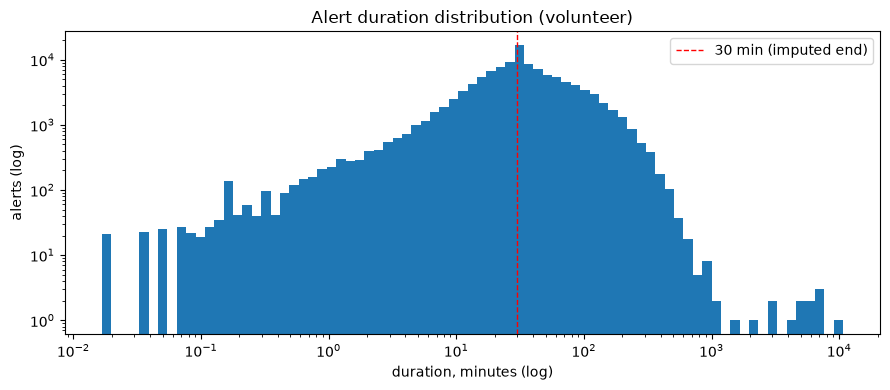

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
pos = df.duration_min[df.duration_min > 0]
ax.hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 80))
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(30, color="red", ls="--", lw=1, label="30 min (imputed end)")
ax.set_xlabel("duration, minutes (log)"); ax.set_ylabel("alerts (log)"); ax.set_title("Alert duration distribution (volunteer)")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_duration_hist.png", dpi=120)

### 5b. Are the > 24 h alerts real?

Several western oblasts got multi-day alerts starting within the same 3 minutes (e.g. 2026-04-17 16:52–16:55 UTC).
That pattern looks like a missed end signal, not real threat. Check: inside each long volunteer alert, what did
the official data record for the same oblast?

In [12]:
rows = []
for _, r in df[df.duration_min > 24 * 60].iterrows():
    w = off[(off.oblast == r.region) & (off.started_at < r.finished_at) & (off.finished_at > r.started_at)]
    rows.append({"region": r.region, "started_at": r.started_at, "volunteer_h": round(r.duration_min / 60, 1),
                 "official_alerts_inside": len(w),
                 "longest_official_h": round((w.finished_at - w.started_at).dt.total_seconds().max() / 3600, 1) if len(w) else 0.0})
pd.DataFrame(rows)

,region,started_at,volunteer_h,official_alerts_inside,longest_official_h
0,Zaporizka oblast,2022-03-04 08:02:43+00:00,178.3,0,0.0
1,Chernivetska oblast,2025-03-03 09:45:47+00:00,77.9,4,0.4
2,Zakarpatska oblast,2025-11-07 23:07:47+00:00,47.8,24,1.2
3,Chernivetska oblast,2025-11-07 23:09:40+00:00,47.8,10,1.2
4,Lvivska oblast,2026-01-29 01:30:51+00:00,90.7,0,0.0
5,Zakarpatska oblast,2026-04-17 16:52:42+00:00,122.4,7,0.5
6,Ternopilska oblast,2026-04-17 16:55:41+00:00,121.0,6,0.5
7,Khmelnytska oblast,2026-04-17 16:55:46+00:00,108.0,4,0.3
8,Chernivetska oblast,2026-04-17 16:55:46+00:00,177.2,6,1.6
9,Zhytomyrska oblast,2026-07-24 09:47:00+00:00,36.5,12,0.9


Official data shows only many short alerts (≤ 1.6 h) inside these windows, or none at all. These are
**missed end signals not flagged as `naive`** — they must be treated as data errors in Step 2.

### 5c. Choosing the cap threshold (alerts of 6 h and longer)

For each volunteer alert ≥ 6 h (inside the official data period) we compute `off_cover`: the share of the
alert window covered by the **union** of official alerts (any level) in the same oblast. Raion-level alerts can
chain, so a single-alert comparison would undercount. `off_cover ≈ 1` → genuine long alert; `≈ 0` → missed end.

In [13]:
def union_cover(region: str, s: pd.Timestamp, e: pd.Timestamp) -> float:
    w = off[(off.oblast == region) & (off.started_at < e) & (off.finished_at > s)].sort_values("started_at")
    total, cur_s, cur_e = 0.0, None, None
    for a, b in zip(w.started_at.clip(lower=s), w.finished_at.clip(upper=e)):
        if cur_e is None or a > cur_e:
            if cur_e is not None:
                total += (cur_e - cur_s).total_seconds()
            cur_s, cur_e = a, b
        else:
            cur_e = max(cur_e, b)
    if cur_e is not None:
        total += (cur_e - cur_s).total_seconds()
    return total / (e - s).total_seconds()

long6 = df[(df.duration_min >= 360) & (df.started_at >= off.started_at.min()) & (df.finished_at <= off.started_at.max())].copy()
long6["off_cover"] = [union_cover(r.region, r.started_at, r.finished_at) for r in long6.itertuples()]
long6["bin"] = pd.cut(long6.duration_min / 60, [6, 8, 12, 24, 1e4], right=False, labels=["6-8h", "8-12h", "12-24h", ">=24h"])
long6.groupby("bin", observed=True).off_cover.agg(
    n="size", median="median", genuine_share=lambda x: (x >= 0.8).mean(), error_share=lambda x: (x < 0.3).mean()).round(2)

,n,median,genuine_share,error_share
bin,,,,
6-8h,244,1.00,0.90,0.09
8-12h,86,1.00,0.85,0.15
12-24h,9,0.03,0.22,0.78
>=24h,12,0.01,0.00,1.00


In [14]:
# by region: where do low-cover (likely erroneous) long alerts come from?
long6.groupby("region").agg(n=("off_cover", "size"), median_cover=("off_cover", "median"),
                            low_cover=("off_cover", lambda x: (x < 0.3).sum())).sort_values("n", ascending=False).round(2)

,n,median_cover,low_cover
region,,,
Donetska oblast,83,1.00,0
Dnipropetrovska oblast,68,1.00,0
Zaporizka oblast,29,1.00,1
Kirovohradska oblast,24,1.00,6
Volynska oblast,24,0.00,23
Mykolaivska oblast,15,1.00,1
Khersonska oblast,15,1.00,0
Kharkivska oblast,13,1.00,0
Poltavska oblast,12,1.00,0


In [15]:
long6[long6.duration_min >= 12 * 60].sort_values("started_at")[["region", "started_at", "duration_min", "off_cover"]].round(2)

C:\Users\andri\AppData\Local\Temp\ipykernel_4708\2473038590.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  long6[long6.duration_min >= 12 * 60].sort_values("started_at")[["region", "started_at", "duration_min", "off_cover"]].round(2)


,region,started_at,duration_min,off_cover
1370,Chernihivska oblast,2022-03-19 02:40:42+00:00,854.70,1.00
16077,Khersonska oblast,2023-01-25 19:59:36+00:00,884.95,1.00
60493,Cherkaska oblast,2025-01-14 03:12:17+00:00,935.22,0.21
63565,Chernivetska oblast,2025-03-03 09:45:47+00:00,4674.17,0.01
66523,Mykolaivska oblast,2025-04-26 06:58:44+00:00,738.95,0.00
75840,Volynska oblast,2025-09-14 06:07:07+00:00,940.75,0.00
79988,Zakarpatska oblast,2025-11-07 23:07:47+00:00,2870.60,0.03
79989,Chernivetska oblast,2025-11-07 23:09:40+00:00,2869.55,0.03
87019,Lvivska oblast,2026-01-29 01:30:51+00:00,5439.52,0.00
95041,Zakarpatska oblast,2026-04-17 16:52:42+00:00,7345.08,0.01


**Decision: cap at 12 h.** ≥ 24 h: 12/12 errors. 12–24 h: 7/9 errors (the 2 genuine ones are 2022–2023
front-line alerts in Chernihiv/Kherson oblasts). 6–12 h: 85–90 % genuine (Donetsk, Dnipro… front-line regions), and
most low-cover cases there come from **Volyn**, which is a separate problem (section 11), not missed ends.
A lower threshold would destroy genuine front-line alerts; region-specific thresholds would be over-engineering.
Using official data to correct labels was rejected: it is unavailable for the test period (stale since 2026-09-07),
so train and test labels would be cleaned differently.

## 6. Permanent-alert regions

Regions where the alert is (almost) always on make the target trivially 1 and inflate metrics.
We measure the share of hours under alert per region over the last 365 days using a quick hourly coverage
(an alert covers hour h if it overlaps `[h, h+1h)`). Step 2 will implement this properly with tests.

In [16]:
def hourly_cover(events: pd.DataFrame) -> pd.DataFrame:
    """Unique (region, hour) pairs touched by any alert. Quick EDA version."""
    events = events.reset_index(drop=True)
    starts = events.started_at.dt.floor("h")
    ends = (events.finished_at - pd.Timedelta(microseconds=1)).dt.floor("h")
    n = (((ends - starts) / pd.Timedelta(hours=1)).astype(int) + 1).clip(lower=1)
    idx = np.repeat(events.index.values, n.values)
    offs = np.concatenate([np.arange(k) for k in n.values])
    hours = pd.DatetimeIndex(starts.loc[idx].values).tz_localize("UTC") + pd.to_timedelta(offs, unit="h")
    return pd.DataFrame({"region": events.region.loc[idx].values, "hour": hours}).drop_duplicates()

last_day = df.started_at.max().floor("D")
recent = df[df.started_at >= last_day - pd.Timedelta(days=365)]
cov = hourly_cover(recent)
share = (cov.groupby("region").size() / (365 * 24)).sort_values(ascending=False)
longest = recent.groupby("region").duration_min.max().div(60).round(1)
perm = pd.DataFrame({"share_hours_alerted_365d": share.round(3), "longest_alert_h_365d": longest})
perm = perm.sort_values("share_hours_alerted_365d", ascending=False)
perm

,share_hours_alerted_365d,longest_alert_h_365d
region,,
Kharkivska oblast,0.634,7.3
Dnipropetrovska oblast,0.591,5.6
Sumska oblast,0.506,4.0
Chernihivska oblast,0.460,6.0
Zaporizka oblast,0.417,6.4
Mykolaivska oblast,0.394,4.5
Poltavska oblast,0.359,6.0
Khersonska oblast,0.351,10.2
Donetska oblast,0.340,10.5


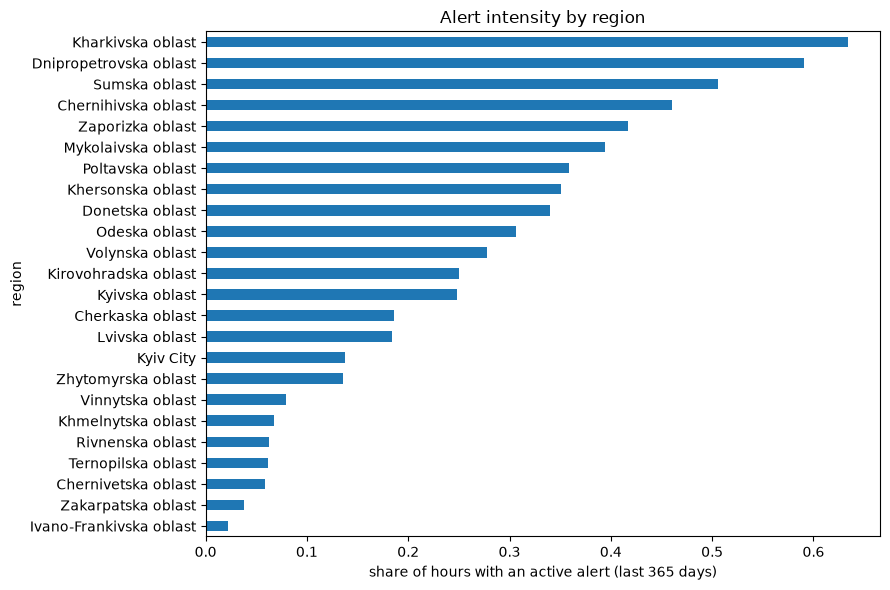

In [17]:
fig, ax = plt.subplots(figsize=(9, 6))
perm.share_hours_alerted_365d.sort_values().plot.barh(ax=ax)
ax.set_xlabel("share of hours with an active alert (last 365 days)"); ax.set_title("Alert intensity by region")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_region_share.png", dpi=120)

## 7. Overlaps & duplicates

In [18]:
s = df.sort_values(["region", "started_at"]).reset_index(drop=True)
print("exact duplicate rows:", s.duplicated(["region", "started_at", "finished_at"]).sum())
prev_max_end = s.groupby("region").finished_at.transform(lambda x: x.cummax().shift())
overlap = s.started_at < prev_max_end
print("alerts starting before the previous alert in the same region ended:", overlap.sum(), f"({overlap.mean():.2%})")
s[overlap][["region", "started_at", "finished_at", "naive", "duration_min"]].head()

exact duplicate rows: 0
alerts starting before the previous alert in the same region ended: 0 (0.00%)


,region,started_at,finished_at,naive,duration_min


Overlaps are harmless for an *any alert during the hour* target: we take the union of intervals.

## 8. Activity over time — regime changes?

,region,naive
started_at,,
2026-08-30 00:00:00+00:00,1084,0.029520
2026-09-06 00:00:00+00:00,1057,0.045412
2026-09-13 00:00:00+00:00,933,0.066452
2026-09-20 00:00:00+00:00,1014,0.063116
2026-09-27 00:00:00+00:00,1152,0.068576
2026-10-04 00:00:00+00:00,1001,0.091908
2026-10-11 00:00:00+00:00,1194,0.095477
2026-10-18 00:00:00+00:00,29,0.000000


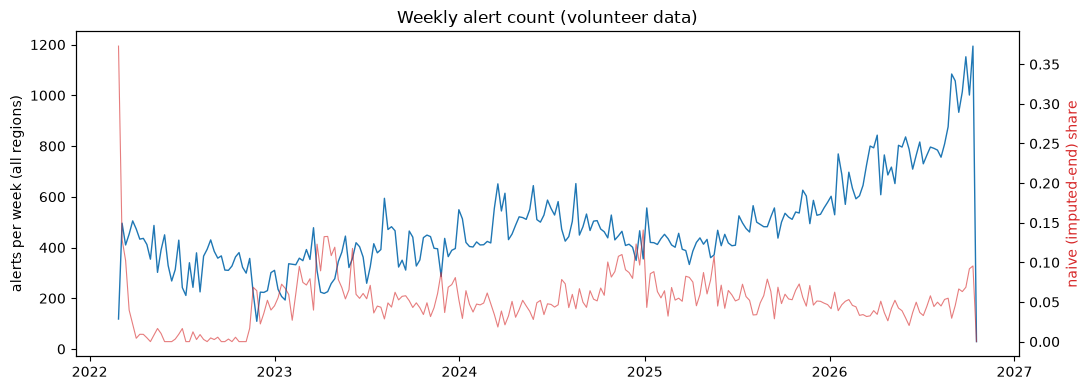

In [19]:
wk = df.set_index("started_at").resample("W").agg({"region": "size", "naive": "mean"})
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wk.index, wk.region, lw=1)
ax.set_ylabel("alerts per week (all regions)"); ax.set_title("Weekly alert count (volunteer data)")
ax2 = ax.twinx(); ax2.plot(wk.index, wk.naive, color="tab:red", lw=0.8, alpha=0.6)
ax2.set_ylabel("naive (imputed-end) share", color="tab:red")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_weekly_alerts.png", dpi=120)
wk.tail(8)

month
2025-09    145.0
2025-10    147.0
2025-11    158.0
2025-12    154.0
2026-01    167.0
2026-02    150.0
2026-03    183.0
2026-04    186.0
2026-05    190.0
2026-06    175.0
2026-07    190.0
2026-08    205.0
2026-09    226.0
2026-10     88.0
Freq: M, dtype: float64

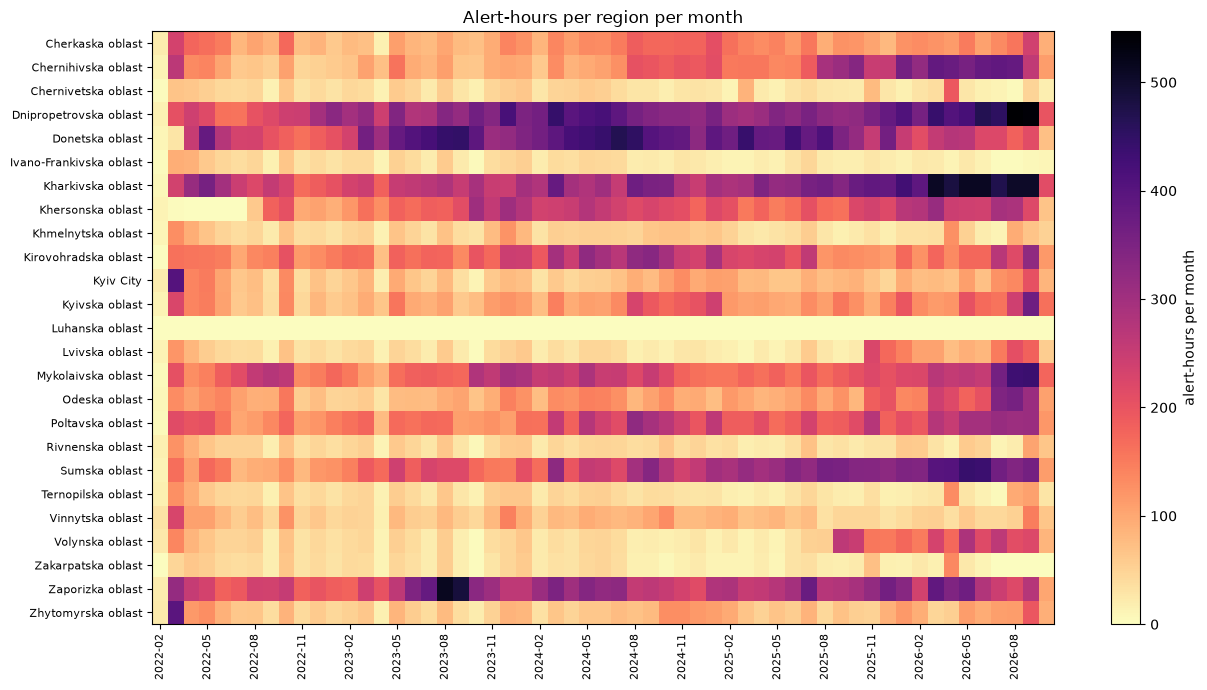

In [20]:
cov_all = hourly_cover(df)
mon = (cov_all.assign(month=cov_all.hour.dt.tz_localize(None).dt.to_period("M"))
       .groupby(["region", "month"]).size().unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(mon.values, aspect="auto", cmap="magma_r")
ax.set_yticks(range(len(mon.index))); ax.set_yticklabels(mon.index, fontsize=8)
xt = list(range(0, mon.shape[1], 3)); ax.set_xticks(xt); ax.set_xticklabels([str(mon.columns[i]) for i in xt], rotation=90, fontsize=8)
fig.colorbar(im, label="alert-hours per month"); ax.set_title("Alert-hours per region per month")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_region_month_heatmap.png", dpi=120)
(mon.sum() / (mon.shape[0])).tail(14).round(0)  # mean alert-hours per region per month

## 9. Seasonality preview (Kyiv local time, last 365 days)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
by_hour,0.277,0.271,0.245,0.243,0.25,0.251,0.245,0.246,0.229,0.236,...,0.23,0.246,0.26,0.282,0.291,0.294,0.271,0.233,0.261,0.263


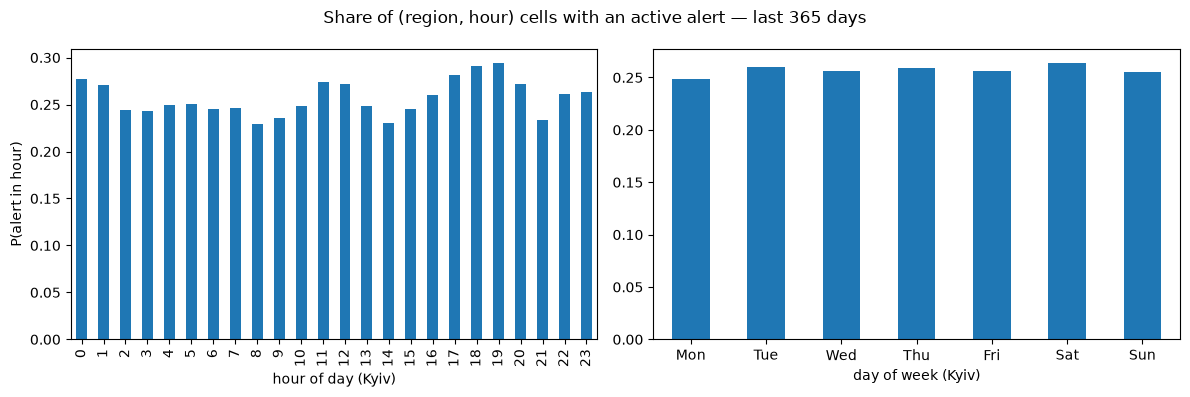

In [21]:
local = cov.hour.dt.tz_convert(KYIV_TZ)
n_regions = cov.region.nunique()
by_hour = cov.groupby(local.dt.hour).size() / (365 * n_regions)
by_dow = cov.groupby(local.dt.dayofweek).size() / (365 / 7 * 24 * n_regions)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour.plot.bar(ax=axes[0]); axes[0].set_xlabel("hour of day (Kyiv)"); axes[0].set_ylabel("P(alert in hour)")
by_dow.plot.bar(ax=axes[1]); axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[1].set_xlabel("day of week (Kyiv)")
fig.suptitle("Share of (region, hour) cells with an active alert — last 365 days")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_seasonality.png", dpi=120)
pd.DataFrame({"by_hour": by_hour.round(3)}).T

## 10. Does the volunteer oblast signal match official raion-level alerts?

Since Dec 2025 official alerts are mostly per raion. What does an *oblast* alert in the volunteer data mean now —
"whole oblast" or "any part of the oblast"? Hour by hour, we compare volunteer coverage with official coverage
where an oblast counts as alerted if **any** official alert (oblast/raion/hromada) inside it was active.

In [22]:
def agreement(start: str, end: str) -> pd.Series:
    v = hourly_cover(df[(df.started_at >= start) & (df.started_at < end)]).assign(vol=1)
    o = hourly_cover(off[(off.started_at >= start) & (off.started_at < end)].rename(columns={"oblast": "region"})).assign(off=1)
    j = v.merge(o, on=["region", "hour"], how="outer").fillna(0)
    both = ((j.vol == 1) & (j.off == 1)).sum()
    return pd.Series({"cells_vol": int(j.vol.sum()), "cells_off": int(j.off.sum()), "both": int(both),
                      "P(off | vol)": both / j.vol.sum(), "P(vol | off)": both / j.off.sum()})

pd.DataFrame({"2024-H2 (oblast era)": agreement("2024-07-01", "2025-01-01"),
              "2026-03..08 (raion era)": agreement("2026-03-01", "2026-09-01")}).round(3)

,2024-H2 (oblast era),2026-03..08 (raion era)
cells_vol,22534.000,28218.000
cells_off,30458.000,40352.000
both,20801.000,24714.000
P(off | vol),0.923,0.876
P(vol | off),0.683,0.612


## 11. Data-collection anomalies found in Step 2

**11a. Volyn and Lviv diverge from official data.** Monthly per-region agreement (hour level).

In [23]:
def monthly_agreement(region: str, start: str = "2025-06-01", end: str = "2026-09-07") -> pd.DataFrame:
    v = hourly_cover(df[(df.region == region) & (df.started_at >= start) & (df.started_at < end)]).assign(vol=1)
    o_ev = off[(off.oblast == region) & (off.started_at >= start) & (off.started_at < end)].rename(columns={"oblast": "region"})
    o = hourly_cover(o_ev).assign(off=1)
    j = v.merge(o, on=["region", "hour"], how="outer").fillna(0)
    j["month"] = j.hour.dt.tz_localize(None).dt.to_period("M")
    g = j.assign(both=j.vol * j.off).groupby("month")[["vol", "off", "both"]].sum()
    g["P(off|vol)"] = (g.both / g.vol).round(2)
    return g.T

for r in ["Volynska oblast", "Lvivska oblast", "Rivnenska oblast"]:
    print(r); display(monthly_agreement(r))

Volynska oblast


month,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
vol,30.0,53.0,54.00,264.00,248.00,154.00,152.00,175.00,151.00,231.0,171.00,286.00,216.0,264.00,211.00,39.00
off,38.0,64.0,33.00,35.00,28.00,23.00,34.00,40.00,55.00,26.0,16.00,36.00,28.0,4.00,6.00,5.00
both,30.0,53.0,24.00,22.00,20.00,21.00,26.00,32.00,43.00,22.0,13.00,31.00,22.0,4.00,4.00,5.00
P(off|vol),1.0,1.0,0.44,0.08,0.08,0.14,0.17,0.18,0.28,0.1,0.08,0.11,0.1,0.02,0.02,0.13


Lvivska oblast


month,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
vol,24.0,58.00,27.00,16.0,22.00,226.0,173.0,144.00,105.00,106.0,74.00,90.00,83.00,150.00,209.00,54.0
off,32.0,57.00,28.00,26.0,28.00,29.0,21.0,19.00,36.00,26.0,15.00,29.00,12.00,4.00,3.00,0.0
both,24.0,50.00,26.00,16.0,20.00,22.0,17.0,16.00,27.00,21.0,13.00,25.00,12.00,4.00,3.00,0.0
P(off|vol),1.0,0.86,0.96,1.0,0.91,0.1,0.1,0.11,0.26,0.2,0.18,0.28,0.14,0.03,0.01,0.0


Rivnenska oblast


month,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
vol,35.0,69.0,26.0,34.0,23.0,30.0,31.0,61.0,58.00,30.0,17.00,58.0,50.00,12.0,20.00,9.00
off,50.0,85.0,35.0,47.0,34.0,29.0,41.0,80.0,77.00,43.0,18.00,77.0,63.00,16.0,18.00,8.00
both,35.0,69.0,26.0,34.0,23.0,24.0,31.0,61.0,57.00,30.0,16.00,58.0,48.00,12.0,13.00,6.00
P(off|vol),1.0,1.0,1.0,1.0,1.0,0.8,1.0,1.0,0.98,1.0,0.94,1.0,0.96,1.0,0.65,0.67


From Sep 2025 (Volyn) and Nov 2025 (Lviv) the volunteer series records ~5–10x more alert-hours than official
data, and only ~10 % of them have any official alert. Neighbouring Rivne stays consistent. So the *meaning* of the
volunteer label for these two oblasts changed (unknown cause: maybe local/raion-level alerts or other alert types
now posted as oblast alerts). We keep them (target = what volunteers record) but report this as a regime change.

**11b. Rounded timestamps 2026-07-12 .. 2026-09-25.** By chance ~1 % of records have both start and end on a
multiple of 10 s. In this window, it is 25–100 % for every region — a sign that the upstream collection changed.

days > 30 %: 76 2026-07-12 .. 2026-09-25


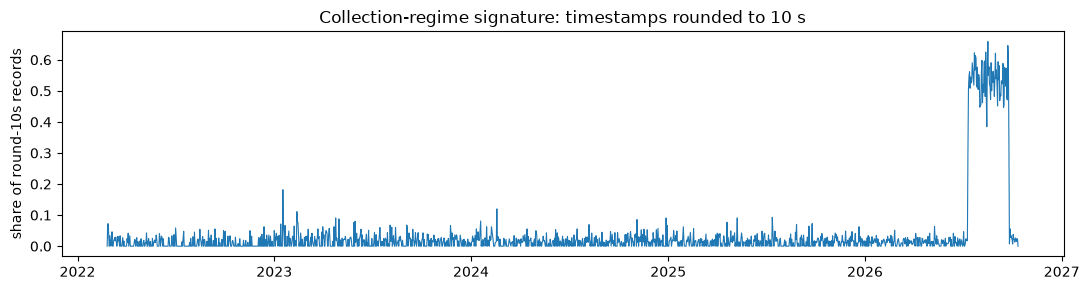

In [24]:
r10 = (df.started_at.dt.second % 10 == 0) & (df.finished_at.dt.second % 10 == 0)
daily = r10.groupby(df.started_at.dt.floor("D")).mean()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(daily.index, daily.values, lw=0.8)
ax.set_ylabel("share of round-10s records"); ax.set_title("Collection-regime signature: timestamps rounded to 10 s")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_round_timestamps.png", dpi=120)
on = daily[daily > 0.3]
print("days > 30 %:", len(on), on.index.min().date(), "..", on.index.max().date())

In the same months, overall agreement P(off|vol) drops from ~0.91 to 0.82 (Jul–Aug 2026, section 10 style).
Implication: label noise is higher right before and inside the evaluation period.